# Drought index calculation for two Mediterranean regions

In [2]:
import pygrib
import matplotlib.pyplot as plt
plt.rcParams['font.size'] = 16
#plt.rcParams["font.family"] = "Arial"
plt.rcParams['font.serif'] = ['Times New Roman']
import matplotlib.colors as colors
from matplotlib.colors import BoundaryNorm
from mpl_toolkits.basemap import Basemap
from mpl_toolkits.basemap import shiftgrid
import numpy as np
import eccodes as ec
import os
import scipy.stats as stats
import statsmodels.api as statsmodels
import datetime as dt
import pandas as pd
import geopandas as gpd
import sys
#import xclim as xclim
import calendar
import netCDF4 as nc4
import xarray as xr
import regionmask


import warnings
warnings.filterwarnings('ignore')
#sys.path.insert(0, '..')
#sys.path.insert(0, '../..')

In [3]:
# import helper functions
print(os.getcwd())
from helpers.helpers_plotting import plot_spi_timeseries, plot_precip_timeseries, create_diverging_colorscheme, plot_droughtmap#, plot_countrymap
from helpers.helpers import identify_events, count_events, sum_dict_lists, get_event_duration, count_occurrences
from helpers.geodata import calculate_gridarea, grid2df, mask_gridpoints_in_polygon, mask_3darray
#from helpers.helpers_ecmwf import load_grb_file
from spidi.spidi.spidi import calculate_si
from spidi.spidi.helpers import convert_mmperday_to_mmpermonth

/etc/ecmwf/nfs/dh2_home_a/nejk/code/drought-on-demand


## Main settings

In [89]:
import seaborn as sns
sns.set_theme(rc={'figure.figsize':(12,4)})


# settings
spi_levels = [-3, -2, -1.5, -1, -0.1, 0.1, 1, 1.5, 2, 3]
plot_type  = 'pcolormesh'
debug = True

lpath     = "/ec/vol/centaur/nejk/drought_monitor"
cwd       = "/home/nejk/code/drought-on-demand"

In [5]:
# paths
drought_index = "SPEI"
windows       = [1,3,6,12]
ref_period    = "1991to2020"
stream        = "moda"
ryyyy_start   = int(ref_period[:4])
ryyyy_end     = int(ref_period[6:10])
print(ryyyy_start)
print(ryyyy_end)
yyyy_start    = "1940"
yyyy_end      = "2024"
print(yyyy_start)
print(yyyy_end)

1991
2020
1940
2024


### Create color scheme

In [6]:
# create colorscheme
cmap_spi, clevels = create_diverging_colorscheme("brown_white_green", start_color = (102/255, 51/255, 0), mid_color = (1, 1, 1), end_color = (51/255, 102/255, 0), 
                                                 levels = spi_levels, levels4pcolormesh=True if plot_type == "pcolormesh" else False)
color_list = [colors.rgb2hex(cmap_spi(i)) for i in range(cmap_spi.N)]

### Handle dates

In [7]:
dates = pd.date_range(start="1990-01-01",end="2025-10-01", freq='M')
print(dates)
print(dates.size)

DatetimeIndex(['1990-01-31', '1990-02-28', '1990-03-31', '1990-04-30',
               '1990-05-31', '1990-06-30', '1990-07-31', '1990-08-31',
               '1990-09-30', '1990-10-31',
               ...
               '2024-12-31', '2025-01-31', '2025-02-28', '2025-03-31',
               '2025-04-30', '2025-05-31', '2025-06-30', '2025-07-31',
               '2025-08-31', '2025-09-30'],
              dtype='datetime64[ns]', length=429, freq='ME')
429


In [8]:
pdate_seq = [dt.datetime.strptime(str(i)[0:10], "%Y-%m-%d") for i in dates]
print(type(pdate_seq))

<class 'list'>


## Masks

### Land mask and barren area mask

In [9]:
# binary land mask
lfile      = f"{lpath}/landmask_era5_global.nc"
lmask      = xr.open_dataset(lfile)['lsm']
lmask      = lmask.where( lmask.values == 1 ) # set 0s to nan
# land fraction
lffile     = f"{lpath}/landmask_era5_global_frac.nc"
lmask_frac = xr.open_dataset(lffile)['var172']
# barren area mask: 1 - do NOT use, 0 - use!
vfile = "/home/nejk/code/dryfall_oper/helpers_oper/barren_mask.nc"
bmask = xr.open_dataset(vfile)


### Mediaterranean Mask

In [10]:

# use external shapefile to incl contended territories?
shpfile = gpd.read_file("./regions/IPCC-WGI-reference-regions-v4.shp")
print(shpfile.head())
#shpfile.plot()
shpfile=shpfile.to_crs('epsg:4326')
extent = (shpfile[shpfile["Name"] == "Mediterranean"]).bounds
lon1   = extent.minx.values[0]
lon2   = extent.maxx.values[0]
lat1   = extent.miny.values[0]
lat2   = extent.maxy.values[0]


### MEDITERRANEAN
# from Joey: the "Name" you want is "Mediterranean" and then we have subregions within that WMED (10 > lon), and EMED (10 < lon)
print(shpfile[shpfile["Name"] == "Mediterranean"])
medmask = regionmask.mask_geopandas((shpfile[shpfile["Name"] == "Mediterranean"]), lmask.lon, lmask.lat)
medmask = xr.where(medmask >= 1, 1, np.nan)
medmask = xr.where( (bmask['barren_mask'][0,:,:] == 1) , np.nan, medmask)
medmask_cut = medmask.sel(lon=slice(lon1, lon2), lat=slice(lat2, lat1))
plt.figure()
#medmask.plot()
# and manual subreguions
# WMED
wmedmask = medmask
wmedmask = xr.where(wmedmask.lon < 10, wmedmask, np.nan)
wmedmask = xr.where( (bmask['barren_mask'][0,:,:] == 1) , np.nan, wmedmask)
wmedmask_cut = wmedmask.sel(lon=slice(lon1, lon2), lat=slice(lat2, lat1))
#plt.figure(); wmedmask.plot()
# EMED
emedmask = medmask
emedmask = xr.where(emedmask.lon >= 10, emedmask, np.nan)
emedmask = xr.where( (bmask['barren_mask'][0,:,:] == 1) , np.nan, emedmask)
emedmask_cut = emedmask.sel(lon=slice(lon1, lon2), lat=slice(lat2, lat1))
#plt.figure(); emedmask.plot()


       Continent  Type               Name Acronym  \
0          POLAR  Land  Greenland/Iceland     GIC   
1  NORTH-AMERICA  Land  N.W.North-America     NWN   
2  NORTH-AMERICA  Land  N.E.North-America     NEN   
3  NORTH-AMERICA  Land    W.North-America     WNA   
4  NORTH-AMERICA  Land    C.North-America     CNA   

                                            geometry  
0  POLYGON ((-10.00000 62.00000, -10.43750 62.000...  
1  POLYGON ((-105.00000 50.00000, -105.43860 50.0...  
2  POLYGON ((-50.00000 50.00000, -50.44000 50.000...  
3  POLYGON ((-130.00000 50.00000, -129.56140 50.0...  
4  POLYGON ((-90.00000 50.00000, -90.00000 49.561...  
        Continent        Type           Name Acronym  \
19  EUROPE-AFRICA  Land-Ocean  Mediterranean     MED   

                                             geometry  
19  POLYGON ((-10.00000 30.00000, -10.00000 30.428...  


<Figure size 640x480 with 0 Axes>

## Reanalysis data

### Read P and P-PET data

In [11]:
# P-PET
ifile_name    = "helpers/era5_data/data_retrieval/wb_all.nc"
ifile         = os.path.join(cwd, ifile_name)
pmpet         = xr.open_dataset(ifile)
print(pmpet)
# P
ifile_name    = "helpers/era5_data/data_retrieval/precip_all.nc"
ifile         = os.path.join(cwd, ifile_name)
precip        = xr.open_dataset(ifile)
print(precip)

<xarray.Dataset> Size: 2GB
Dimensions:  (time: 429, lon: 1440, lat: 721)
Coordinates:
  * time     (time) datetime64[ns] 3kB 1990-01-01T06:00:00 ... 2025-09-01T06:...
  * lon      (lon) float64 12kB -180.0 -179.8 -179.5 ... 179.2 179.5 179.8
  * lat      (lat) float64 6kB 90.0 89.75 89.5 89.25 ... -89.5 -89.75 -90.0
Data variables:
    wb       (time, lat, lon) float32 2GB ...
Attributes:
    CDI:          Climate Data Interface version 2.5.1 (https://mpimet.mpg.de...
    Conventions:  CF-1.6
    institution:  European Centre for Medium-Range Weather Forecasts
    history:      Thu Oct 23 13:05:15 2025: cdo --eccodes -expr,wb=tp-pev -me...
    CDO:          Climate Data Operators version 2.5.1 (https://mpimet.mpg.de...
<xarray.Dataset> Size: 2GB
Dimensions:  (time: 429, lon: 1440, lat: 721)
Coordinates:
  * time     (time) datetime64[ns] 3kB 1990-01-01T06:00:00 ... 2025-09-01T06:...
  * lon      (lon) float64 12kB -180.0 -179.8 -179.5 ... 179.2 179.5 179.8
  * lat      (lat) float64 6k

In [18]:
# ATTN, maybe not working properly because mask only 2D, but pmpet and precip 3D

# P-PET 
pmpet_wmed = pmpet.where(wmedmask)
print(pmpet_wmed)
pmpet_emed = pmpet.where(emedmask)
print(pmpet_emed)

# P only
precip_wmed = precip.where(wmedmask)
print(precip_wmed)
precip_emed = precip.where(emedmask)
print(precip_emed)

<xarray.Dataset> Size: 2GB
Dimensions:  (time: 429, lat: 721, lon: 1440)
Coordinates:
  * time     (time) datetime64[ns] 3kB 1990-01-01T06:00:00 ... 2025-09-01T06:...
  * lon      (lon) float64 12kB -180.0 -179.8 -179.5 ... 179.2 179.5 179.8
  * lat      (lat) float64 6kB 90.0 89.75 89.5 89.25 ... -89.5 -89.75 -90.0
Data variables:
    wb       (time, lat, lon) float32 2GB 0.7181 0.7181 0.7181 ... 0.3376 0.3376
Attributes:
    CDI:          Climate Data Interface version 2.5.1 (https://mpimet.mpg.de...
    Conventions:  CF-1.6
    institution:  European Centre for Medium-Range Weather Forecasts
    history:      Thu Oct 23 13:05:15 2025: cdo --eccodes -expr,wb=tp-pev -me...
    CDO:          Climate Data Operators version 2.5.1 (https://mpimet.mpg.de...
<xarray.Dataset> Size: 2GB
Dimensions:  (time: 429, lat: 721, lon: 1440)
Coordinates:
  * time     (time) datetime64[ns] 3kB 1990-01-01T06:00:00 ... 2025-09-01T06:...
  * lon      (lon) float64 12kB -180.0 -179.8 -179.5 ... 179.2 179.5 

## Calculate region-based drought indicators

1643624.0426519185
2181932.890688853


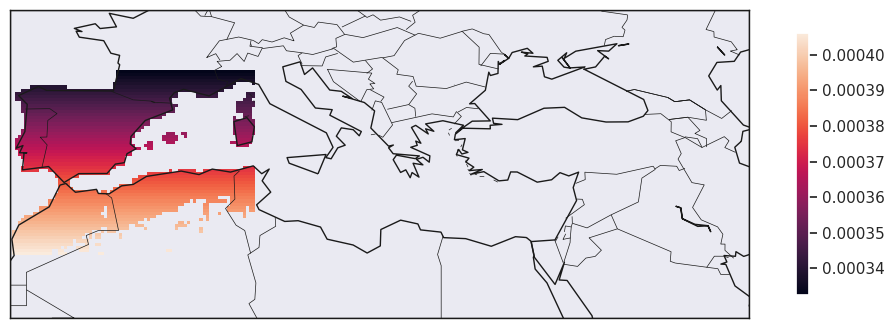

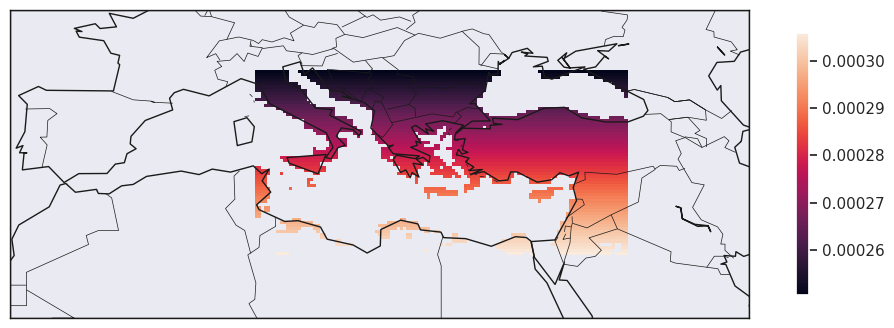

In [93]:
EARTHRADIUS = 6371  # earth radius [km]
def calculate_gridarea(lats_centr, res, nlon):
    ## make use of numpy vectorization
    lats1 = (lats_centr + (res / 2)) * np.pi / 180  # np.sin requires radians
    lats2 = (lats_centr - (res / 2)) * np.pi / 180
    areas = (
        (np.pi / 180) * (EARTHRADIUS ** 2) * np.abs(np.sin(lats1) - np.sin(lats2)) * res
    )

    ## overwrite any areas of 0 (at the poles) with np.NaN to prevent problems
    areas[np.where(areas == 0.0)] = np.NaN  # only works for arrays
    # return array of dimension nlat x nlon
    area_2d = np.swapaxes(np.tile(areas, (nlon, 1)), 0, 1)
    return area_2d

area_2d = calculate_gridarea(lmask.lat, res=abs(lmask.lon[1]-lmask.lon[0]), nlon=len(lmask.lon))  

wmed_area_2d = wmedmask.values * area_2d
wmed_area_2d[wmed_area_2d==0] = np.nan
wmed_area_total = np.nansum(wmed_area_2d)
if debug:
    print(wmed_area_total)
wmed_area_weights = wmed_area_2d/wmed_area_total

emed_area_2d = emedmask.values * area_2d
emed_area_2d[emed_area_2d==0] = np.nan
emed_area_total = np.nansum(emed_area_2d)
if debug:
    print(emed_area_total)
emed_area_weights = emed_area_2d/emed_area_total


if debug:
    fig = plt.figure()
    m = Basemap(projection='cyl', llcrnrlon=-180, \
            urcrnrlon=180.,llcrnrlat=lmask.lat.min(),urcrnrlat=lmask.lat.max(), \
            resolution='c')
    x, y = m(lmask.lon, lmask.lat)
    m.drawcoastlines()
    m.drawmapboundary()
    m.drawcountries()
    plt.xlim((-10,50))
    plt.ylim((25,50))
    ax1 = m.pcolormesh(x, y, wmed_area_weights, shading='auto')
    plt.colorbar(ax1, orientation='vertical', shrink=0.85)
    plt.show()

    fig = plt.figure()
    m = Basemap(projection='cyl', llcrnrlon=-180, \
            urcrnrlon=180.,llcrnrlat=lmask.lat.min(),urcrnrlat=lmask.lat.max(), \
            resolution='c')
    x, y = m(lmask.lon, lmask.lat)
    m.drawcoastlines()
    m.drawmapboundary()
    m.drawcountries()
    plt.xlim((-10,50))
    plt.ylim((25,50))
    ax1 = m.pcolormesh(x, y, emed_area_weights, shading='auto')
    plt.colorbar(ax1, orientation='vertical', shrink=0.85)
    plt.show()

### Calulate average P and P-PET

429
(429,)
429
429
(429,)
429


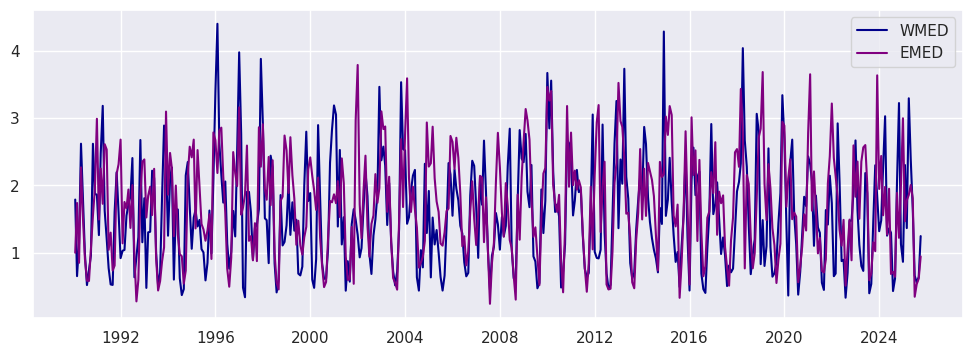

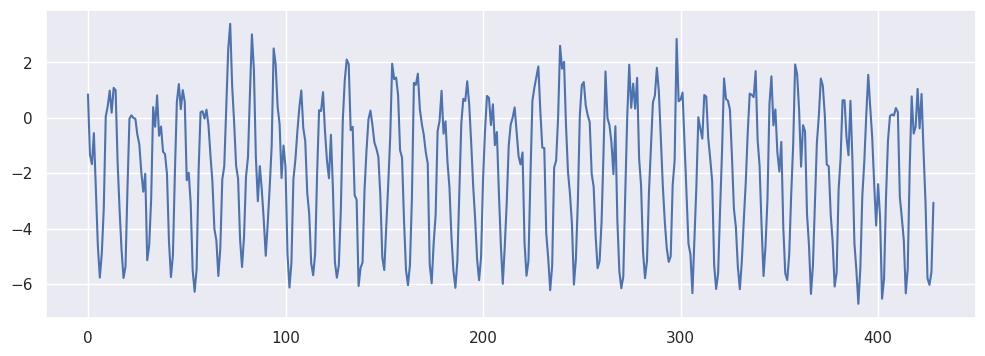

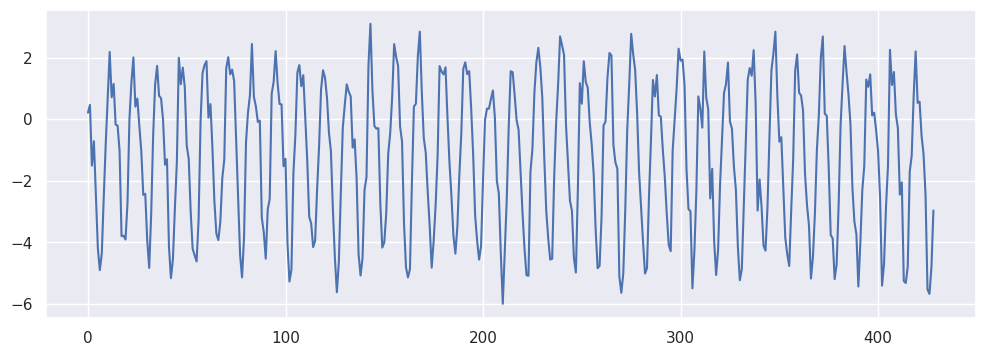

In [100]:
print(precip_wmed['tp'].shape[0])
precip_wmed_ts = np.zeros(precip_wmed['tp'].shape[0])
precip_emed_ts = np.zeros(precip_emed['tp'].shape[0])

for it in range(len(precip_wmed_ts)):
    #precip_wmed_ts[it] = np.nansum(precip_wmed['tp'].isel(time=it).values * wmed_area_2d / wmed_area_total)
    #precip_emed_ts[it] = np.nansum(precip_emed['tp'].isel(time=it).values * emed_area_2d / emed_area_total)
    precip_wmed_ts[it] = np.nansum(precip['tp'].isel(time=it).values * wmed_area_weights)
    precip_emed_ts[it] = np.nansum(precip['tp'].isel(time=it).values * emed_area_weights)

print(precip_wmed_ts.shape)
print(dates.size)

plt.figure()
plt.plot(dates, precip_wmed_ts, color="darkblue", label="WMED")
plt.plot(dates, precip_emed_ts, color="purple", label="EMED")
plt.legend()

if drought_index == "SPEI":
    print(pmpet_wmed['wb'].shape[0])
    pmpet_wmed_ts = np.zeros(pmpet_wmed['wb'].shape[0])
    pmpet_emed_ts = np.zeros(pmpet_emed['wb'].shape[0])
    
    for it in range(len(pmpet_wmed_ts)):
        #print(type(pmpet_country['wb'].isel(time=it)))
        #pmpet_country_ts[it] = pmpet_country['wb'].isel(time=it).weighted(weights).mean(dim=("lat", "lon")) # not working yet
        pmpet_wmed_ts[it] = np.nansum(pmpet_wmed['wb'].isel(time=it).values * wmed_area_2d / wmed_area_total)
        pmpet_emed_ts[it] = np.nansum(pmpet_emed['wb'].isel(time=it).values * emed_area_2d / emed_area_total)

    print(pmpet_wmed_ts.shape)
    print(dates.size)
    
    plt.figure()
    plt.plot(pmpet_wmed_ts)

    plt.figure()
    plt.plot(pmpet_emed_ts)

### Calculate region-average P and drought index

<class 'numpy.ndarray'>
[ 55.49641002  18.29102262  35.44642354  78.59800522  55.2692357
  29.17629716  16.1434984   23.19747914  28.82573137  81.18953341
  56.10097245  57.81226134  39.13760082  69.27945321  98.64859192
  48.75144887  37.43067784  23.18635248  16.440809    16.19606665
  48.08635257  68.0884209   47.86499018  28.54497195  31.94114878
  30.24590006  48.1243439   51.60397894  56.96248487  72.20920775
  19.72507591  29.22237763  36.98034859  82.92357658  34.69303174
  56.13120919  14.82956203  36.49603657  40.69282514  66.57479586
  65.39033283  30.51798592  15.78113635  21.72814019  54.92361399
  89.59760545  71.0065917   38.86271409  64.66220107  63.45002665
  18.6572638   49.41820116  50.93953174  18.68984572  11.52140688
  14.29633365  64.48273898  72.79059763  50.84449411  32.84764546
  47.20651747  45.84108495  43.12960797  44.65243731  32.69860558
  30.16052128  18.29798269  26.38088615  48.82363563  30.73949413
  62.95338979 105.29285419 136.4200187   76.34979599 

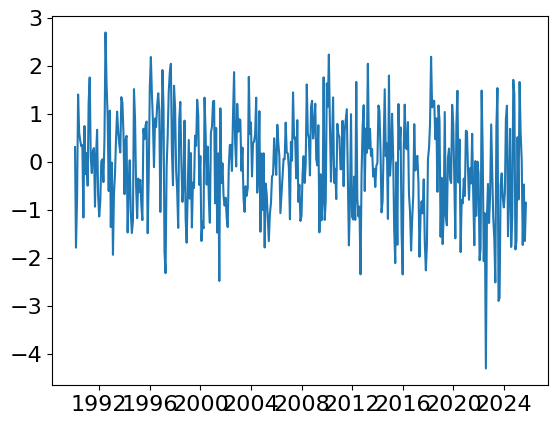

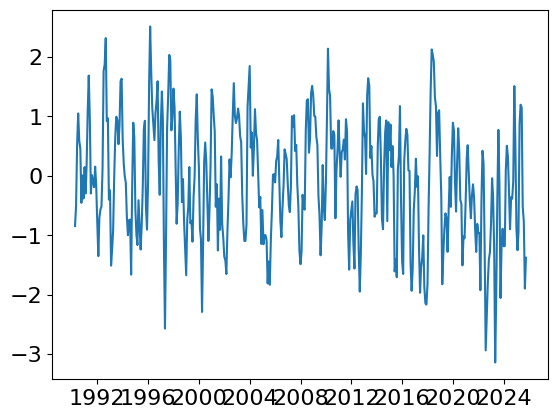

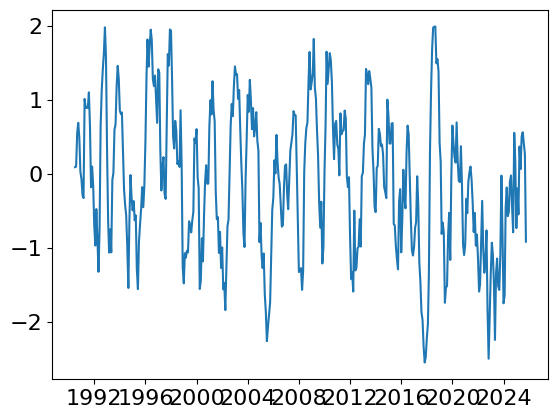

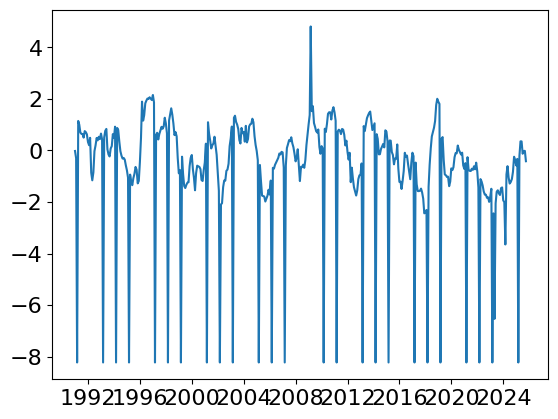

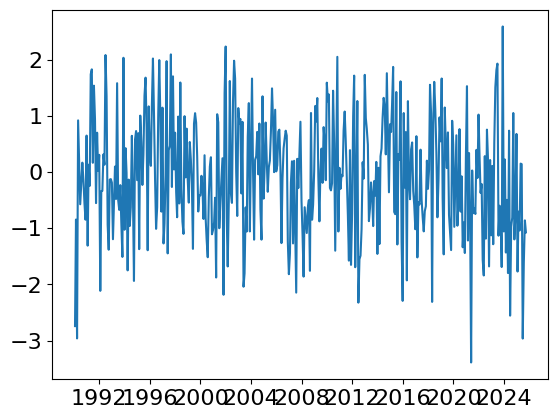

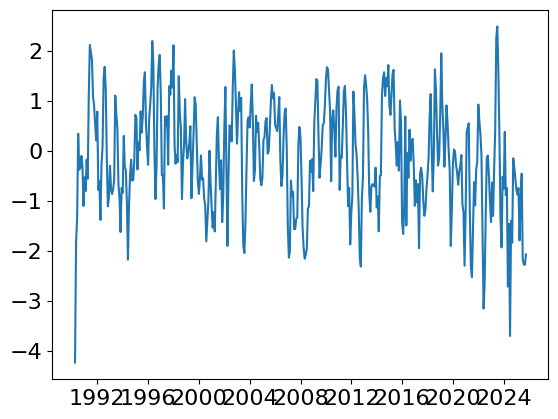

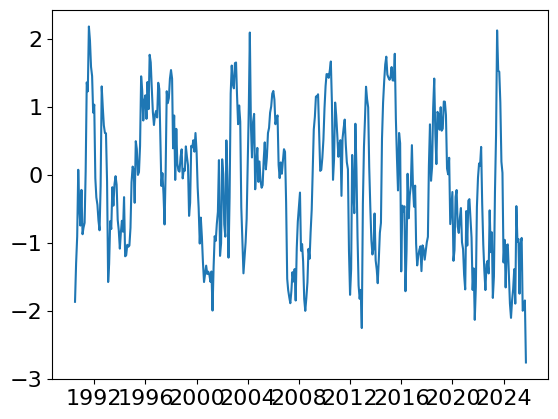

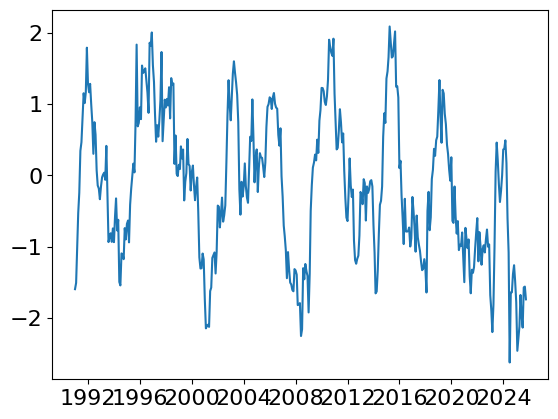

In [43]:
istart = np.where(dates.year == 2003)[0][0]
# WMED
print(type(precip_wmed_ts))
precip_wmed_tss = {}
wdfdata = pd.DataFrame(precip_wmed_ts, index=pdate_seq)
wdfdata.index = pd.to_datetime(wdfdata.index)
wdfdata = convert_mmperday_to_mmpermonth(wdfdata, list(wdfdata.columns.values))
print((wdfdata.to_numpy().squeeze()))
# EMED
precip_emed_tss = {}
edfdata = pd.DataFrame(precip_emed_ts, index=pdate_seq)
edfdata.index = pd.to_datetime(edfdata.index)
edfdata.index.strftime("%Y-%m")
edfdata = convert_mmperday_to_mmpermonth(edfdata, list(edfdata.columns.values))
print((edfdata.to_numpy().squeeze()))
# create one final dataframe for regions EMED, WMED
myindex =dates[istart:].strftime("%Y-%m")
print(myindex)
mypd = pd.DataFrame({'date' : myindex, 'region': 'EMED', 'precip_mm_per_month': edfdata.to_numpy().squeeze()[istart:]})
print(mypd)
dummy = pd.DataFrame({'date' : myindex, 'region': 'WMED', 'precip_mm_per_month': wdfdata.to_numpy().squeeze()[istart:]})
print(dummy)
mypd = pd.concat([mypd, dummy])
print(mypd)
mypd.to_csv(f"MEDS_precip.csv", decimal='.', float_format='%.2f', index= False)


# now, SPEI
if drought_index == "SPEI":

    # WMED
    spei_wmed_ts = {}
    dfdata = pd.DataFrame(pmpet_wmed_ts, index=pdate_seq)
    dfdata.index = pd.to_datetime(dfdata.index)
    dfdata = convert_mmperday_to_mmpermonth(dfdata, list(dfdata.columns.values))
    dfdata_ref = dfdata.iloc[ (dfdata.index.year >= ryyyy_start) & (dfdata.index.year <= ryyyy_end) ]
    print((dfdata.index.year >= ryyyy_start).any())
    print((dfdata.index.year <= ryyyy_end).any())
    print(ryyyy_end)
    print((dfdata_ref))
    
    for window in windows:
        print(f"Processing country average of {drought_index.lower()}{window}...")
    
        tspi_wmed = calculate_si(dfdata, dfdata_ref = dfdata_ref, window = window, distribution = 'genlogistic', integration_frequency_string = '%m-%d',
            n_events_min = 5, max_zeros = 0.99, remove_zeros = False, pzero_replace = False, pzero_center_mass = False)[f"si{window}_0"]
      
        # write to dictionary
        ivar      = f"{drought_index.lower()}{window}"
        spei_wmed_ts[ivar] = tspi_wmed.values[:]
        del(tspi_wmed)
    
        plt.figure()
        plt.plot(dates, spei_wmed_ts[ivar])

    del(dfdata, dfdata_ref)
    
    # EMED
    spei_emed_ts = {}
    dfdata = pd.DataFrame(pmpet_emed_ts, index=pdate_seq)
    dfdata.index = pd.to_datetime(dfdata.index)
    dfdata = convert_mmperday_to_mmpermonth(dfdata, list(dfdata.columns.values))
    dfdata_ref = dfdata.iloc[ (dfdata.index.year >= ryyyy_start) & (dfdata.index.year <= ryyyy_end) ]
    print((dfdata.index.year >= ryyyy_start).any())
    print((dfdata.index.year <= ryyyy_end).any())
    print(ryyyy_end)
    print((dfdata_ref))
    
    for window in windows:
        print(f"Processing country average of {drought_index.lower()}{window}...")
    
        tspi_emed = calculate_si(dfdata, dfdata_ref = dfdata_ref, window = window, distribution = 'genlogistic', integration_frequency_string = '%m-%d',
            n_events_min = 5, max_zeros = 0.99, remove_zeros = False, pzero_replace = False, pzero_center_mass = False)[f"si{window}_0"]
      
        # write to dictionary
        ivar      = f"{drought_index.lower()}{window}"
        spei_emed_ts[ivar] = tspi_emed.values[:]
        del(tspi_emed)
    
        plt.figure()
        plt.plot(dates, spei_emed_ts[ivar])

### Monthly SPEI plots

1
180
Processing from 2005-01-31 00:00:00 to 2025-09-30 00:00:00
3
180
Processing from 2005-01-31 00:00:00 to 2025-09-30 00:00:00
6
180
Processing from 2005-01-31 00:00:00 to 2025-09-30 00:00:00
12
180
Processing from 2005-01-31 00:00:00 to 2025-09-30 00:00:00
1
180
Processing from 2005-01-31 00:00:00 to 2025-09-30 00:00:00
3
180
Processing from 2005-01-31 00:00:00 to 2025-09-30 00:00:00
6
180
Processing from 2005-01-31 00:00:00 to 2025-09-30 00:00:00
12
180
Processing from 2005-01-31 00:00:00 to 2025-09-30 00:00:00


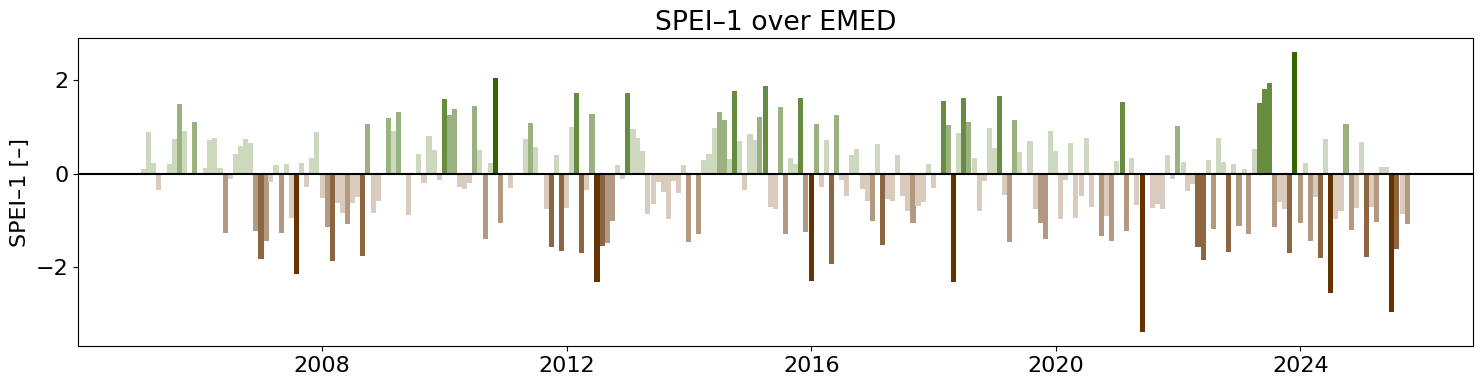

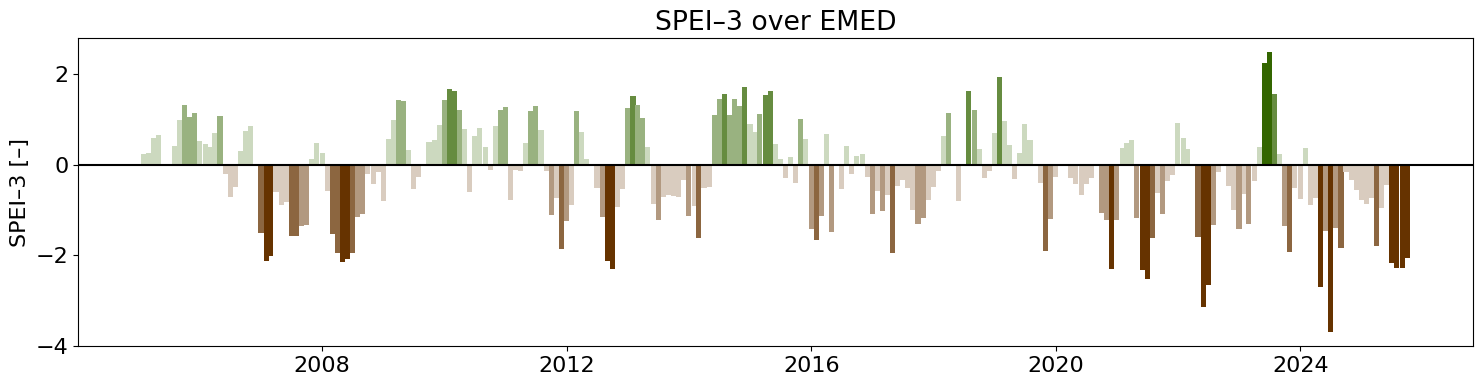

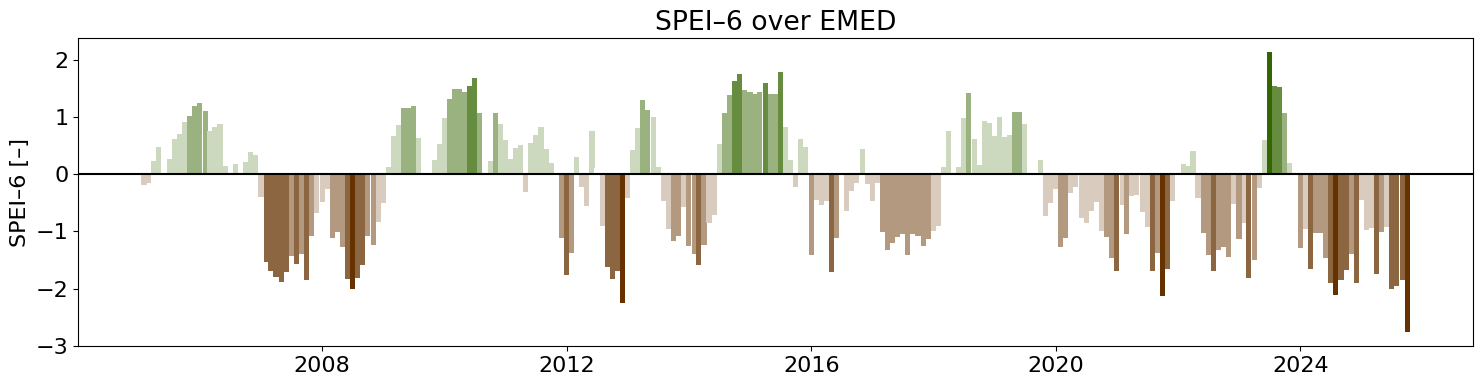

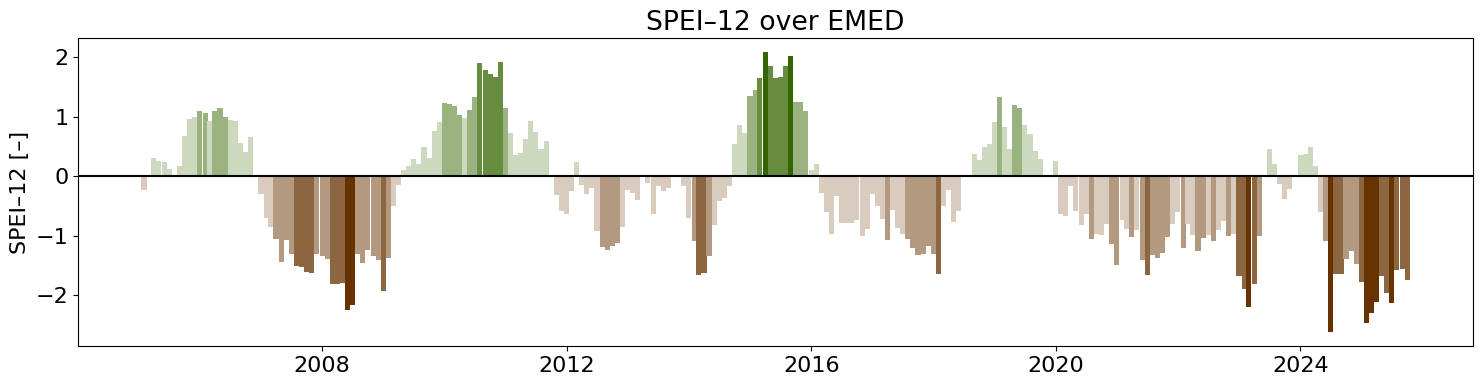

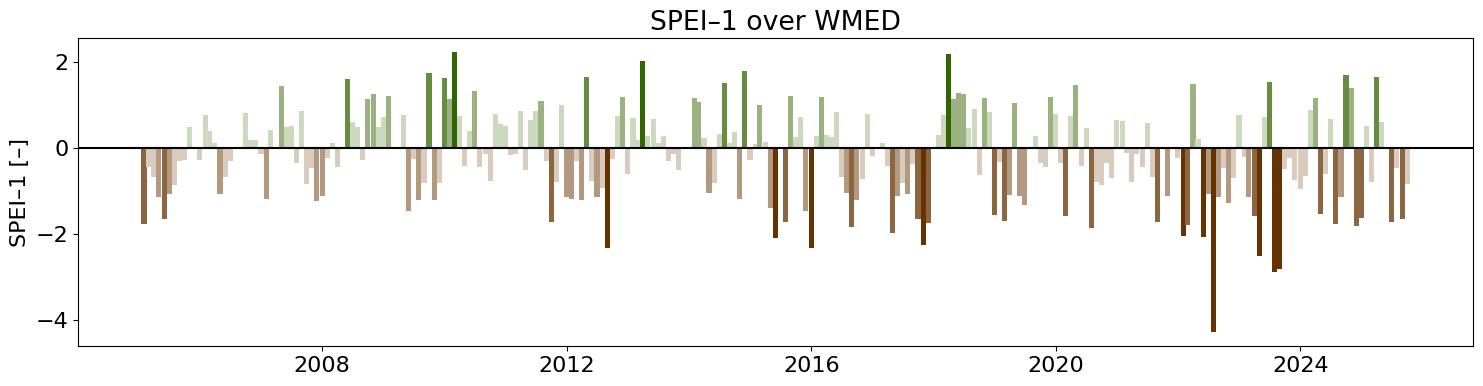

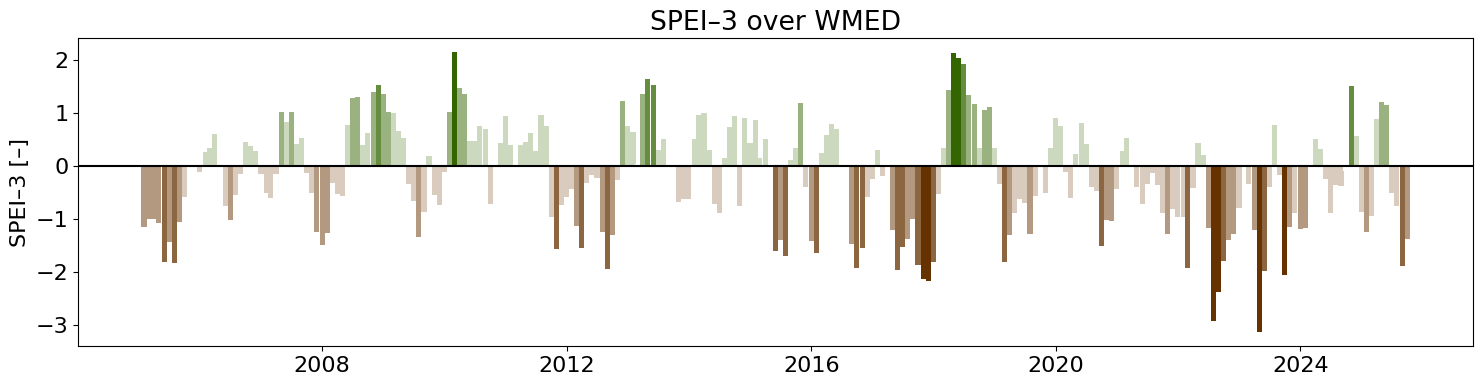

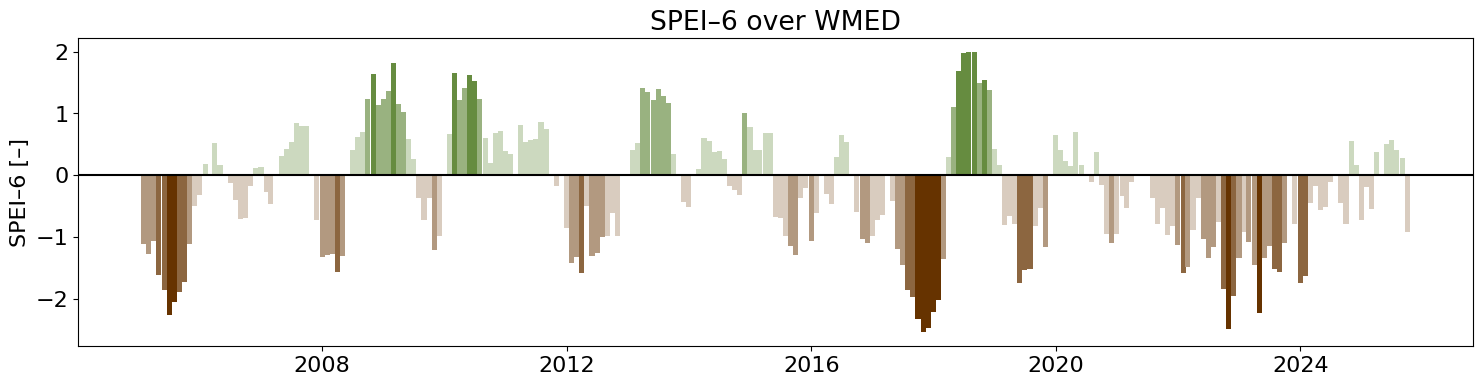

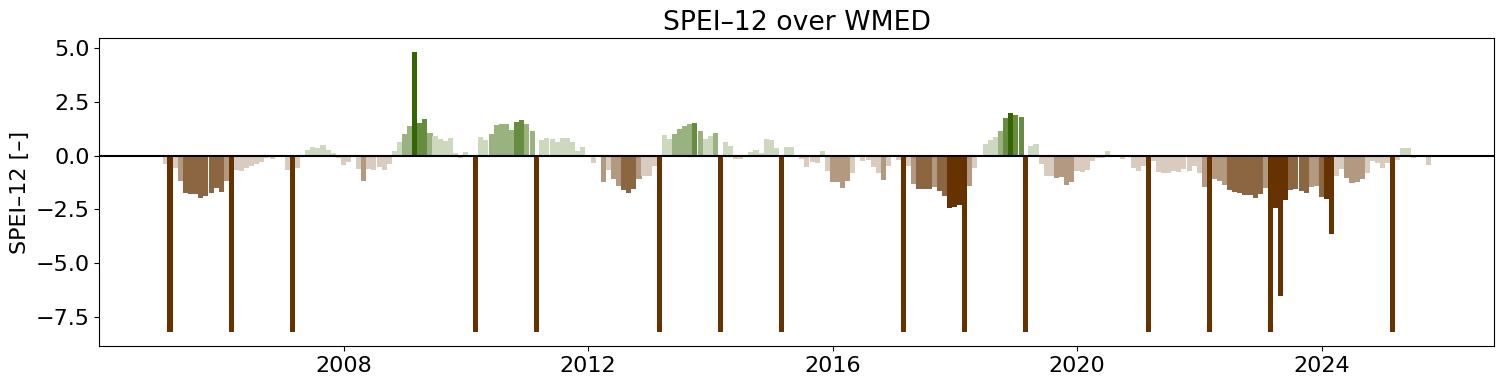

In [15]:
for window in windows:

    print(window)
    ivar      = f"{drought_index.lower()}{window}"

    plt.figure(figsize=(18,4))
    
    istart = np.where(dates.year == 2005)[0][0]
    print(istart)

    x = dates[istart:]
    print(f"Processing from {x[0]} to {x[-1]}")
    xyear = [ix.year for ix in x]
    
    if drought_index == "SPI":
        y = list(spei_emed_ts[f"{drought_index.lower()}{window}"][istart:])
    if drought_index == "SPEI":
        y = list(spei_emed_ts[f"{drought_index.lower()}{window}"][istart:])
        
    # color for each spi time step, including mild categories and white between -0.1 and 0.1
    y_colors = [{np.isnan(p): color_list[4], p<=-2: color_list[0], -2<p<=-1.5: color_list[1], -1.5<p<=-1: color_list[2], -1<p<=-0.1: color_list[3], -0.1<p<0.1: color_list[4], 0.1<=p<1: color_list[5], 1<=p<1.5: color_list[6], 1.5<=p<2: color_list[7], p>=2: color_list[8]}[True] for p in y]
    # color for each spi time step, excluding mild categories and grey between -1 and 1
    #y_colors = [{np.isnan(p): color_list[4], p<=-2: color_list[0], -2<p<=-1.5: color_list[1], -1.5<p<=-1: color_list[2], -1<p<1: '#7F7F7F', 1<=p<1.5: color_list[6], 1.5<=p<2: color_list[7], p>=2: color_list[8]}[True] for p in y]
    plt.bar(x, y, color=y_colors, align='center', width=365/(12))
    #print(x[xyear.index(ryyyy_end)])
    #plt.axvspan(x[xyear.index(ryyyy_start)], x[xyear.index(ryyyy_end)], facecolor='#CCCCCC', alpha=0.5)
    plt.bar(x, y, color=y_colors, align='center', width=365/(12))
    plt.axhline(y=0, color = 'black', linestyle = '-')
    #plt.xlabel("Date")
    plt.ylabel(f"{drought_index}–{window} [–]")
    plt.title(f"{drought_index}–{window} over EMED")
    
    #plt.xlim(x[istart],x[-1])

    # custom legend
    from matplotlib.lines import Line2D
    custom_lines = [Line2D([0], [0], color=color_list[0], lw=4),
                    Line2D([0], [0], color=color_list[1], lw=4),
                    Line2D([0], [0], color=color_list[2], lw=4),
                    #Line2D([0], [0], color=color_list[3], lw=4),
                    Line2D([0], [0], color='#7F7F7F', lw=4),
                    #Line2D([0], [0], color=color_list[5], lw=4),
                    Line2D([0], [0], color=color_list[6], lw=4),
                    Line2D([0], [0], color=color_list[7], lw=4),
                    Line2D([0], [0], color=color_list[8], lw=4)]

    #plt.legend(custom_lines, ['extremely dry', 'severely dry', 'moderately dry','near-normal','moderately wet','severely wet','extremely wet'], ncol=7, loc='upper center')
    #print(y)
        
    del(x)
    del(y)
    del(y_colors)

    plt.savefig(f"/home/nejk/code/drought-on-demand/figures/EMED_{drought_index}{window}_monthly_classical_latest.png", facecolor="white",  edgecolor='none')
    #plt.savefig(f"/home/nejk/code/drought_on_demand/drought_stripes/figures/Southern{admin_name}_{drought_index}{window}_monthly_classical_latest.png", facecolor="white",  edgecolor='none')
    #plt.savefig(f"/home/nejk/code/drought_on_demand/drought_stripes/figures/Southern{admin_name}_{drought_index}{window}_monthly_classical_latest.pdf", facecolor="white",  edgecolor='none')
    #print(f"/home/nejk/code/drought_on_demand/drought_stripes/figures/Southern{admin_name}_{drought_index}{window}_monthly_classical_latest.png")
    #print(f"/home/nejk/code/drought_on_demand/drought_stripes/figures/Southern{admin_name}_{drought_index}{window}_monthly_classical_latest.pdf")


for window in windows:

    print(window)
    ivar      = f"{drought_index.lower()}{window}"

    plt.figure(figsize=(18,4))
    
    istart = np.where(dates.year == 2005)[0][0]
    print(istart)

    x = dates[istart:]
    print(f"Processing from {x[0]} to {x[-1]}")
    xyear = [ix.year for ix in x]
    
    if drought_index == "SPI":
        y = list(spei_wmed_ts[f"{drought_index.lower()}{window}"][istart:])
    if drought_index == "SPEI":
        y = list(spei_wmed_ts[f"{drought_index.lower()}{window}"][istart:])
        
    # color for each spi time step, including mild categories and white between -0.1 and 0.1
    y_colors = [{np.isnan(p): color_list[4], p<=-2: color_list[0], -2<p<=-1.5: color_list[1], -1.5<p<=-1: color_list[2], -1<p<=-0.1: color_list[3], -0.1<p<0.1: color_list[4], 0.1<=p<1: color_list[5], 1<=p<1.5: color_list[6], 1.5<=p<2: color_list[7], p>=2: color_list[8]}[True] for p in y]
    # color for each spi time step, excluding mild categories and grey between -1 and 1
    #y_colors = [{np.isnan(p): color_list[4], p<=-2: color_list[0], -2<p<=-1.5: color_list[1], -1.5<p<=-1: color_list[2], -1<p<1: '#7F7F7F', 1<=p<1.5: color_list[6], 1.5<=p<2: color_list[7], p>=2: color_list[8]}[True] for p in y]
    plt.bar(x, y, color=y_colors, align='center', width=365/(12))
    #print(x[xyear.index(ryyyy_end)])
    #plt.axvspan(x[xyear.index(ryyyy_start)], x[xyear.index(ryyyy_end)], facecolor='#CCCCCC', alpha=0.5)
    plt.bar(x, y, color=y_colors, align='center', width=365/(12))
    plt.axhline(y=0, color = 'black', linestyle = '-')
    #plt.xlabel("Date")
    plt.ylabel(f"{drought_index}–{window} [–]")
    plt.title(f"{drought_index}–{window} over WMED")
    
    #plt.xlim(x[istart],x[-1])

    # custom legend
    from matplotlib.lines import Line2D
    custom_lines = [Line2D([0], [0], color=color_list[0], lw=4),
                    Line2D([0], [0], color=color_list[1], lw=4),
                    Line2D([0], [0], color=color_list[2], lw=4),
                    #Line2D([0], [0], color=color_list[3], lw=4),
                    Line2D([0], [0], color='#7F7F7F', lw=4),
                    #Line2D([0], [0], color=color_list[5], lw=4),
                    Line2D([0], [0], color=color_list[6], lw=4),
                    Line2D([0], [0], color=color_list[7], lw=4),
                    Line2D([0], [0], color=color_list[8], lw=4)]

    #plt.legend(custom_lines, ['extremely dry', 'severely dry', 'moderately dry','near-normal','moderately wet','severely wet','extremely wet'], ncol=7, loc='upper center')
    #print(y)
        
    del(x)
    del(y)
    del(y_colors)

    plt.savefig(f"/home/nejk/code/drought-on-demand/figures/WMED_{drought_index}{window}_monthly_classical_latest.png", facecolor="white",  edgecolor='none')
    #plt.savefig(f"/home/nejk/code/drought_on_demand/drought_stripes/figures/Southern{admin_name}_{drought_index}{window}_monthly_classical_latest.pdf", facecolor="white",  edgecolor='none')
    #print(f"/home/nejk/code/drought_on_demand/drought_stripes/figures/Southern{admin_name}_{drought_index}{window}_monthly_classical_latest.png")
    #print(f"/home/nejk/code/drought_on_demand/drought_stripes/figures/Southern{admin_name}_{drought_index}{window}_monthly_classical_latest.pdf")

## Write final csv

In [18]:

print(window)
ivar      = f"{drought_index.lower()}{window}"

plt.figure(figsize=(18,4))

istart = np.where(dates.year == 2003)[0][0]
print(istart)

x = dates[istart:]
print(f"Processing from {x[0]} to {x[-1]}")
xyear = [ix.year for ix in x]

if drought_index == "SPI":
    yw = list(spei_wmed_ts[f"{drought_index.lower()}{window}"][istart:])
    ye = list(spei_emed_ts[f"{drought_index.lower()}{window}"][istart:])
if drought_index == "SPEI":
    yw = list(spei_wmed_ts[f"{drought_index.lower()}{window}"][istart:])
    ye = list(spei_emed_ts[f"{drought_index.lower()}{window}"][istart:])

# create one final dataframe for regions MED (from aid df), and subregions CMED, EMED, WMED (from aid_subregions df)
myindex =dates[istart:].strftime("%Y-%m")#spei_emed_ts[f"{drought_index.lower()}{window}"][istart:].index.strftime("%Y-%m")
print(myindex)
spei_1 = spei_emed_ts[f"{drought_index.lower()}1"][istart:]
print(spei_1)
spei_3 = spei_emed_ts[f"{drought_index.lower()}3"][istart:]
spei_6 = spei_emed_ts[f"{drought_index.lower()}6"][istart:]
spei_12= spei_emed_ts[f"{drought_index.lower()}12"][istart:]
mypd = pd.DataFrame({'date' : myindex, 'region': 'EMED', 'SPEI_1': spei_1, 'SPEI_3': spei_3, 'SPEI_6': spei_6, 'SPEI_12': spei_12})

myindex =dates[istart:].strftime("%Y-%m")#spei_wmed_ts[f"{drought_index.lower()}{window}"][istart:].index.strftime("%Y-%m")
spei_1 = spei_wmed_ts[f"{drought_index.lower()}1"][istart:]
spei_3 = spei_wmed_ts[f"{drought_index.lower()}3"][istart:]
spei_6 = spei_wmed_ts[f"{drought_index.lower()}6"][istart:]
spei_12= spei_wmed_ts[f"{drought_index.lower()}12"][istart:]
dummy = pd.DataFrame({'date' : myindex, 'region': 'WMED', 'SPEI_1': spei_1, 'SPEI_3': spei_3, 'SPEI_6': spei_6, 'SPEI_12': spei_12})
print(dummy)

mypd = pd.concat([mypd, dummy])
print(mypd)

mypd.to_csv(f"MEDS_SPEI_1_3_6_12.csv", decimal='.', float_format='%.2f', index= False)

12
156
Processing from 2003-01-31 00:00:00 to 2025-09-30 00:00:00
Index(['2003-01', '2003-02', '2003-03', '2003-04', '2003-05', '2003-06',
       '2003-07', '2003-08', '2003-09', '2003-10',
       ...
       '2024-12', '2025-01', '2025-02', '2025-03', '2025-04', '2025-05',
       '2025-06', '2025-07', '2025-08', '2025-09'],
      dtype='object', length=273)
[ 0.85611368  0.94305677 -0.38236847  0.89132834 -2.04168275 -1.80190456
 -0.62990057 -1.05984249  0.62427022  1.22436918 -1.05855304  0.38577575
  1.66137969  0.04865749 -1.20468375  0.2167438   0.27995016  0.71229952
 -0.04247592  0.86148348 -0.6642088  -1.20419604  1.34547876 -0.47433058
  0.10426319  0.87853619  0.2171853  -0.35300981  0.08468492  0.20306914
  0.73108639  1.486591    0.9160124  -0.00356414  1.10651395  0.00987677
  0.11795026  0.71579354  0.75232372  0.11792178 -1.26575915 -0.11258828
  0.41825333  0.58867864  0.73420814  0.64588294 -1.23683778 -1.81869069
 -1.44478999 -0.18619485  0.18956354 -1.27180152  0.1984

<Figure size 1800x400 with 0 Axes>

In [19]:
spei_emed_ts[f"{drought_index.lower()}{window}"][istart:]

array([ 1.10625562e+00,  1.42177183e+00,  1.59742288e+00,  1.43863569e+00,
        1.29810734e+00,  1.12668210e+00,  7.45446322e-01, -1.96541808e-01,
       -5.51640201e-01, -9.14115294e-02, -2.98367185e-01, -1.55490087e-01,
        1.66643865e-01, -1.49100246e-01, -3.10977725e-01, -3.85501704e-01,
        7.89282018e-02,  5.40030355e-01,  4.80564129e-01,  1.06335679e+00,
        5.28713753e-01, -9.83351989e-02,  2.46008067e-01,  3.62429849e-01,
       -2.34485149e-01,  9.88734866e-02,  3.09534842e-01,  2.52297515e-01,
        2.44857288e-01,  1.23338719e-01, -2.45214220e-02,  1.79097646e-01,
        6.74065764e-01,  9.59720657e-01,  9.96259829e-01,  1.09287420e+00,
        1.07096149e+00,  9.29913048e-01,  1.09544155e+00,  1.15351564e+00,
        1.00290412e+00,  9.48664144e-01,  9.34606201e-01,  5.66821849e-01,
        4.15826173e-01,  6.58546459e-01, -1.29518292e-02, -2.98892878e-01,
       -7.06049482e-01, -8.52547580e-01, -1.05244902e+00, -1.44204390e+00,
       -1.07639872e+00, -

## Plot regional precipitation in mm per month from csv

In [62]:
test = pd.read_csv(f"MEDS_precip.csv", decimal='.')
print(test)

        date region  precip_mm_per_month
0    2003-01   EMED                87.95
1    2003-02   EMED                80.53
2    2003-03   EMED                49.86
3    2003-04   EMED                63.86
4    2003-05   EMED                36.20
..       ...    ...                  ...
541  2025-05   WMED                51.17
542  2025-06   WMED                19.80
543  2025-07   WMED                17.36
544  2025-08   WMED                19.86
545  2025-09   WMED                37.44

[546 rows x 3 columns]


(0.0, 130.0)

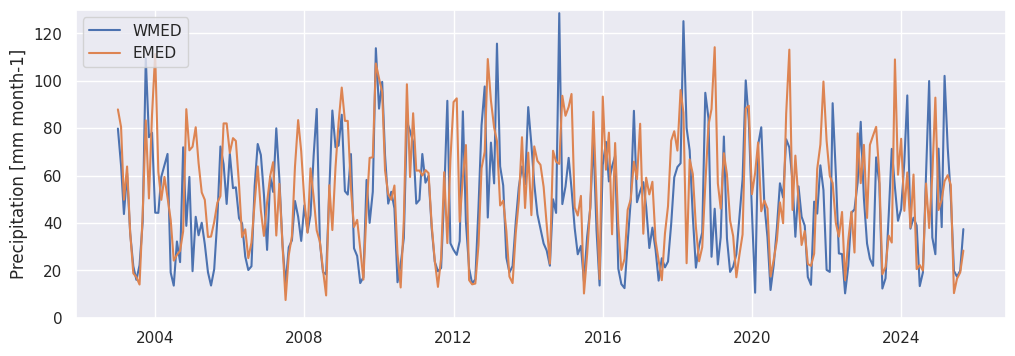

In [87]:
import seaborn as sns
sns.set_theme(rc={'figure.figsize':(12,4)})

y0 = test[test['region']=="WMED"]
y0.index = pd.to_datetime(y0['date'], format="%Y-%m")
y1 = test[test['region']=="EMED"]
y1.index = pd.to_datetime(y1['date'], format="%Y-%m")

ax = sns.lineplot(data=y0, x=y0.index, y='precip_mm_per_month', palette=("red",), label="WMED")
sns.lineplot(ax = ax, data=y1, x=y1.index, y='precip_mm_per_month', palette=("purple",), label="EMED")
plt.xlabel("")
plt.ylabel("Precipitation [mm month-1]")
sns.move_legend(ax,"upper left")
plt.ylim([0,130])